In [1]:
import numpy as np
import scipy as sp
import sys
import os
import matplotlib.pyplot as plt

# One and two body operators
from quant_rotor.Hamiltonian_models.Dense.operators import heisenberg_operators, rotor_operators

from quant_rotor.Hamiltonian_models.Dense.density_matrix import density_matrix_1

# Hamiltonian Constructor
from quant_rotor.Hamiltonian_models.Dense.hamiltonian import hamiltonian_dense
from quant_rotor.Hamiltonian_models.Sparse.hamiltonian import hamiltonian_sparse

# Basis Changes
from quant_rotor.Hamiltonian_models.Dense.basis_transform import NO_transform, combine_transform ,TF_transform ,energy_transform, first_nontrivial_index, min_non_zero

# Exact T-amplitude and energy calculations
from quant_rotor.CCC_iterative_methods.Dense.t_amplitudes_exact import t_1_amplitude_guess_ground_state, t_2_amplitude_guess_ground_state, amplitute_energy

# Iterative CCC
from quant_rotor.CCC_iterative_methods.Dense.t_amplitudes_periodic import t_periodic
from quant_rotor.CCC_iterative_methods.Dense.t_amplitudes_periodic_fast import t_periodic as t_periodic_fast
from quant_rotor.CCC_iterative_methods.Dense.t_amplitudes_periodic_fast_unique import t_periodic as t_periodic_fast_unique

# Integrator
from quant_rotor.CCC_integration_methods.Dense.de_solve_one_thermal import integration_scheme
from quant_rotor.CCC_integration_methods.Dense.de_solve_one_thermal_dense import integration_scheme as integration_scheme_fast
from quant_rotor.CCC_integration_methods.Dense.stat_mech_thermo import U as U_stat
from quant_rotor.CCC_integration_methods.Dense.stat_mech_thermo import Z as Z_stat
from quant_rotor.CCC_integration_methods.Dense.stat_mech_thermo import S as S_stat
from quant_rotor.CCC_integration_methods.Dense.stat_mech_thermo import A as A_stat
from quant_rotor.CCC_integration_methods.Dense.stat_mech_thermo import Z_new, A_new, S_new

In [2]:
def orthonormal_basis_from_vector(v):
    v = np.asarray(v, dtype=float)
    d = v.size

    # Normalize first vector explicitly
    e1 = v

    basis = np.zeros((d, d))
    basis[:, 0] = e1

    # Use Gram-Schmidt for remaining vectors
    for i in range(1, d):
        vec = np.random.randn(d)

        # Orthogonalize against previous basis vectors
        for j in range(i):
            vec -= np.dot(basis[:, j], vec) * basis[:, j]

        norm = np.linalg.norm(vec)
        if norm < 1e-12:
            return orthonormal_basis_from_vector(v)  # retry

        basis[:, i] = vec / norm

    return basis

In [3]:
def dec_t_1(site, state, K, V, periodic, iter=4, lower_limit=1e-6):
    full_transform = np.eye(state)
    iter = 6

    # while True:
    for i in range(iter):

        K_transformed = full_transform.T.conj() @ K @ full_transform
        full_transform_2 = np.kron(full_transform, full_transform)
        V_transformed = (full_transform_2.conj().T @ V @ full_transform_2).reshape(state, state, state, state)

        energy, _, _, t_1_updated, t_2_updated = integration_scheme(site, state, K_transformed, V_transformed, V_transformed, periodic=periodic, t_final=40)

        print(f"Iteration: {i} t_1 - {np.max(np.abs(t_1_updated))}")
        print(f"Iteration: {i} t_2 - {np.max(np.abs(t_2_updated))}")

        ref_0 = np.concatenate((np.array([1]), t_1_updated.reshape(site, state-1)[0]))
        ref_0 = ref_0 / np.linalg.norm(ref_0)

        diagonal_basis = np.zeros((state, state))
        diagonal_basis = orthonormal_basis_from_vector(ref_0)

        full_transform = full_transform @ diagonal_basis
        # i +=1

        # if np.max(np.abs(t_1_updated)) < lower_limit:
        #     break

    return energy[-1], t_1_updated, t_2_updated

In [4]:
def dec_t_1_exact(site, state, n_iter, K, V, periodic):
    full_transform = np.eye(state)

    for i in range(n_iter):

        K_transformed = full_transform.T.conj() @ K @ full_transform
        full_transform_2 = np.kron(full_transform, full_transform)
        V_transformed = (full_transform_2.conj().T @ V @ full_transform_2)

        H_transformed = hamiltonian_dense(site, K_transformed, V_transformed, V_transformed, periodic)

        _, eig_vec = np.linalg.eigh(H_transformed)

        t_1_updated = t_1_amplitude_guess_ground_state(state, site, eig_vec[:, 0])

        print(f"Iteration: {i} t_1 - {np.max(np.abs(t_1_updated))}")

        ref_0 = np.concatenate((np.array([1]), t_1_updated.reshape(site, state-1)[0]))
        ref_0 = ref_0 / np.linalg.norm(ref_0)

        diagonal_basis = np.zeros((state, state))
        diagonal_basis = orthonormal_basis_from_vector(ref_0)

        full_transform = full_transform @ diagonal_basis

    return t_1_updated

# Develop

In [12]:
state = 11
state_NO = 5

site = 5

g = 0.8
periodic = True

In [13]:
K, V = rotor_operators(state, g)
# K_comb, V_comb_xy, V_comb_yx = combine_transform(2, K, V)

In [14]:
# H, K, V = hamiltonian_sparse(state, site, g, periodic=periodic)
H = hamiltonian_dense(3, K, V, V, periodic)

In [15]:
eig_val, eig_vec = np.linalg.eigh(H)

K_NO, V_NO, _, NO_basis = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

In [16]:
t_1, t_2= dec_t_1(site, state_NO, 5, K_NO, V_NO, periodic)

9600
Iteration: 0 t_1 - 0.7168394937279565
Iteration: 0 t_2 - 0.10507949359468179


/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_78536/1173419831.py:2: ComplexWarning: Casting complex values to real discards the imaginary part
  v = np.asarray(v, dtype=float)


10826
Iteration: 1 t_1 - 0.04221050175305063
Iteration: 1 t_2 - 0.06646422737729665
12052
Iteration: 2 t_1 - 0.002310821444193947
Iteration: 2 t_2 - 0.058142123803909034
13278
Iteration: 3 t_1 - 0.0024916683066893205
Iteration: 3 t_2 - 0.06717210185297029


In [ ]:
state = 11
state_NO = 5

site = 5

g = 0.8
periodic = True

g_arr = np.arange(0, 1.5, 0.2)
t_1_max_arr = np.full_like(g_arr, 0)
t_2_max_arr = np.full_like(g_arr, 0)

In [24]:
for i, g in enumerate(g_arr):

    K, V = rotor_operators(state, g)
    H = hamiltonian_dense(3, K, V, V, periodic)
    eig_val, eig_vec = np.linalg.eigh(H)

    K_NO, V_NO, _, NO_basis = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

    print(f"------------------------------ Iter: {i}, g = {g} ------------------------------")
    t_1, t_2= dec_t_1(site, state_NO, 5, K_NO, V_NO, periodic)

    t_1_max_arr[i] = np.max(np.abs(t_1))
    t_2_max_arr[i] = np.max(np.abs(t_2))

------------------------------ Iter: 0, g = 0.0 ------------------------------
14312
Iteration: 0 t_1 - 0.0
Iteration: 0 t_2 - 0.0


/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_78536/1173419831.py:2: ComplexWarning: Casting complex values to real discards the imaginary part
  v = np.asarray(v, dtype=float)


15346
Iteration: 1 t_1 - 0.0
Iteration: 1 t_2 - 0.0
16380
Iteration: 2 t_1 - 0.0
Iteration: 2 t_2 - 0.0
17414
Iteration: 3 t_1 - 0.0
Iteration: 3 t_2 - 0.0
18448
Iteration: 4 t_1 - 0.0
Iteration: 4 t_2 - 0.0
19482
Iteration: 5 t_1 - 0.0
Iteration: 5 t_2 - 0.0
20516
Iteration: 6 t_1 - 0.0
Iteration: 6 t_2 - 0.0
21550
Iteration: 7 t_1 - 0.0
Iteration: 7 t_2 - 0.0
22584
Iteration: 8 t_1 - 0.0
Iteration: 8 t_2 - 0.0
23618
Iteration: 9 t_1 - 0.0
Iteration: 9 t_2 - 0.0
24652
Iteration: 10 t_1 - 0.0
Iteration: 10 t_2 - 0.0
25686
Iteration: 11 t_1 - 0.0
Iteration: 11 t_2 - 0.0
26720
Iteration: 12 t_1 - 0.0
Iteration: 12 t_2 - 0.0


KeyboardInterrupt: 

In [ ]:
H_NO = hamiltonian_dense(site, K_NO, V_NO, V_NO, periodic)

In [ ]:
# eig_val_NO, eig_vec_NO = np.linalg.eigh(H_NO)

In [ ]:
# beta_s, energy, _, t_1_s, t_2_s = integration_scheme(site, state_NO, K_NO, V_NO.reshape(state_NO, state_NO, state_NO, state_NO), V_NO.reshape(state_NO, state_NO, state_NO, state_NO), periodic=periodic, t_final=40)

In [9]:
V_NO[0, 0]

np.complex128(-2.6956658704227414e-31+0j)

In [10]:
H_NO[0, 0]

np.complex128(0.377321513578989+0j)

In [13]:
K_NO[0, 0]

np.complex128(0.0754643027157978+0j)

In [35]:
beta_s, energy, _, t_1_s, t_2_s = integration_scheme(site, state, K, V.reshape(state, state, state, state), V.reshape(state, state, state, state), periodic=periodic, t_final=40)

0.0
9.999999999999999e-05
0.0011
0.0111
0.06859459123732649
0.12533372012570448
0.18361171034706103
0.24388679125721546
0.306566075171258
0.37200492244808014
0.4405328361695568
0.5124373496221152
0.5878896827291885
0.6667825539370864
0.748509064533379
0.8318636580814271
0.9152810232227245
0.9973277003656402
1.0770639492865925
1.1540717745937046
1.2282906898179358
1.2998496914868873
1.3689597659757742
1.4358564617111376
1.5007707595679352
1.5639144388689812
1.6254734642920623
1.6856067243535422
1.744448899884507
1.8021169519975133
1.8587207705346218
1.9143764898533306
1.969219898590474
2.023424623600056
2.077210568012248
2.130834677263383
2.184561456838549
2.2386264572422743
2.2932123206401704
2.348445044167591
2.404403873609239
2.4611351168056173
2.518664210259802
2.5770044076507443
2.6361624419498577
2.6961420062608563
2.7569457766706407
2.8185765105649585
2.881037585815162
2.944333170078149
3.008468167846631
3.073448046682165
3.1392785399436853
3.205965283641495
3.2735134467529545
3.

/Users/gilfrim/Desktop/Projects/Computational_Analysis_of_Many_Rotor_Systems/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/gilfrim/Desktop/Projects/Computational_Analysis_of_Many_Rotor_Systems/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


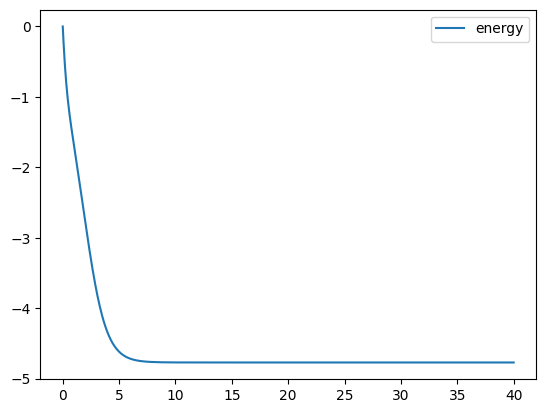

In [36]:
plt.plot(beta_s, energy, label=f"energy")
plt.legend()
plt.show()

In [37]:
# eig_val_NO, eig_vec_NO = np.linalg.eigh(H_NO)

In [38]:
eig_val[0]

np.float64(-2.1839664213704593)

In [39]:
energy[-1]

np.complex128(-4.7701322396533+0j)

In [40]:
energy[-1] - eig_val[0]

np.complex128(-2.586165818282841+0j)

In [41]:
print(np.max(np.abs(t_1_s)))
print(np.max(np.abs(t_2_s)))

0.1540470749734428
0.650653692132057


In [37]:
energy[-1]/20

np.complex128(-0.07806749133960061+0j)

In [10]:
V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)
V = V.reshape(state, state, state, state)

In [11]:
t_1_exact_rot_per = t_1_amplitude_guess_ground_state(state, site, eig_vec[:, 0])
t_2_exact_rot_per = t_2_amplitude_guess_ground_state(state, site, eig_vec[:, 0])

In [12]:
site_test = 5

In [13]:
t_1_set = np.random.rand(site_test, state-1, 1)
t_2_set = np.random.rand(site_test, site_test, state-1, state-1, 1)
K_set = np.random.rand(state, state)
V_set = np.random.rand(state, state, state, state)

In [14]:
E_f_t, t_1_f_t, t_2_f_t, R_1_f_t, R_2_f_t = t_periodic_fast(site_test, K_set, V_set, V_set, t_1_import=t_1_set.reshape(site_test, state-1), t_2_import=t_2_set.reshape(site_test, site_test, state-1, state-1), periodic=periodic)

3


In [15]:
E_t, t_1_t, t_2_t, R_1_t, R_2_t = t_periodic(site_test, K_set, V_set, V_set, "original", t_1_import=t_1_set, t_2_import=t_2_set, periodic=periodic)

original


In [16]:
R_1_f_t

array([[7.304065195129e+21+0.j, 7.603517568088e+22+0.j, 1.511663311234e+21+0.j, 1.619655455494e+21+0.j, 6.182307753335e+21+0.j, 1.036580172027e+21+0.j, 3.134594447998e+21+0.j, 3.477243196919e+23+0.j, 1.229814873762e+21+0.j, 3.619007030958e+23+0.j],
       [7.199047753000e+21+0.j, 7.577540789303e+22+0.j, 1.494627102565e+21+0.j, 1.602428495155e+21+0.j, 6.195976914441e+21+0.j, 1.023495460677e+21+0.j, 3.156987454343e+21+0.j, 3.473560474774e+23+0.j, 1.221555540428e+21+0.j, 3.616542857644e+23+0.j],
       [7.363556848873e+21+0.j, 7.625929032362e+22+0.j, 1.522415675405e+21+0.j, 1.617341139123e+21+0.j, 6.176211001716e+21+0.j, 1.033307202154e+21+0.j, 3.188411969577e+21+0.j, 3.483326765213e+23+0.j, 1.230242998166e+21+0.j, 3.616137978680e+23+0.j],
       [7.271053227881e+21+0.j, 7.610814936556e+22+0.j, 1.507863796915e+21+0.j, 1.602102136018e+21+0.j, 6.197952007578e+21+0.j, 1.021987732798e+21+0.j, 3.215313174198e+21+0.j, 3.484605075442e+23+0.j, 1.223832051433e+21+0.j, 3.618645486784e+23+0.j],
    

In [17]:
(R_1_f_t - R_1_t.reshape(site_test, state-1))

array([[1.468006400e+07+0.j, 1.677721600e+08+0.j, 1.572864000e+06+0.j, 3.407872000e+06+0.j, 1.363148800e+07+0.j, 1.048576000e+06+0.j, 2.621440000e+06+0.j, 6.710886400e+08+0.j, 5.242880000e+05+0.j, 9.395240960e+08+0.j],
       [1.258291200e+07+0.j, 1.677721600e+08+0.j, 4.718592000e+06+0.j, 2.359296000e+06+0.j, 1.048576000e+07+0.j, 1.179648000e+06+0.j, 1.048576000e+06+0.j, 5.368709120e+08+0.j, 1.048576000e+06+0.j, 1.207959552e+09+0.j],
       [1.258291200e+07+0.j, 8.388608000e+07+0.j, 3.670016000e+06+0.j, 2.621440000e+06+0.j, 6.291456000e+06+0.j, 1.179648000e+06+0.j, 2.621440000e+06+0.j, 0.000000000e+00+0.j, 7.864320000e+05+0.j, 1.342177280e+09+0.j],
       [1.887436800e+07+0.j, 1.342177280e+08+0.j, 1.835008000e+06+0.j, 1.835008000e+06+0.j, 7.340032000e+06+0.j, 7.864320000e+05+0.j, 4.194304000e+06+0.j, 4.026531840e+08+0.j, 2.621440000e+05+0.j, 9.395240960e+08+0.j],
       [1.572864000e+07+0.j, 8.388608000e+07+0.j, 2.883584000e+06+0.j, 5.242880000e+05+0.j, 1.258291200e+07+0.j, 2.621440000

In [ ]:
E_f, t_1_fast, t_2_fast, R_1_fast, R_2_fast = t_periodic_fast(4, K_NO, V_NO, V_NO, periodic=periodic, one_cicle=False)

104


In [ ]:
E, t_1, t_2, R_1, R_2 = t_periodic(4, K_NO, V_NO, V_NO, "original", periodic=periodic, one_cicle=False)

original


In [ ]:
beta_s, _, _, t_1_s, t_2_s = integration_scheme(3, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=40)

0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.2775039222215727
0.45172617835185425
0.6348908005960365
0.8269931337544512
1.0285364143582045
1.240269809125774
1.463138002315984
1.698270004423933
1.946990911703879
2.2108486665160125
2.4916541014676956
2.791535481551426
3.113011036753022
3.4590852699874697
3.8333780942295017
4.240300696475354
4.685299772115799
5.175204381273012
5.675204381273012
6.175204381273012
6.675204381273012
7.175204381273012
7.675204381273012
8.175204381273012
8.675204381273012
9.175204381273012
9.675204381273012
10.175204381273012
10.675204381273012
11.175204381273012
11.675204381273012
12.175204381273012
12.675204381273012
13.175204381273012
13.675204381273012
14.175204381273012
14.675204381273012
15.175204381273012
15.675204381273012
16.175204381273012
16.675204381273012
17.175204381273012
17.675204381273012
18.175204381273012
18.675204381273012
19.175204381273012
19.675204381273012
20.175204381273012
20.675204381273012
21.175204381273012
21.675204381273012
2

In [ ]:
beta_f, _, _, t_1_f, t_2_f = integration_scheme_fast(3, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=40)

0.0
9.999999999999999e-05
0.0011
0.0111
0.06593169894156478
0.12065821531836338
0.18094837536580308
0.24635273841295385
0.31763660052320697
0.39595991387791846
0.4830055616425245
0.5805767779683808
0.6897389241385078
0.809819483267285
0.9411013029444355
1.0836004830904398
1.2382814770879378
1.407829036168506
1.5972681094113175
1.8136707584021008
2.064519372042504
2.322739103617859
2.464532647621846
2.606326191625833
2.9777793319823975
3.0935084127661185
3.2092374935498396
3.6404269142007175
3.7477995597151486
3.8551722052295796
4.2145363778520215
4.33344599119614
4.452355604540258
4.8518830076476895
4.971646329385514
5.091409651123339
5.4889391832189975
5.615595771920439
5.74225236062188
6.24225236062188
6.3528141229183595
6.463375885214839
6.736709262489859
6.917394188470972
7.098079114452085
7.321348284922076
7.544617455392066
7.743066400997985
7.941515346603904
8.147434601724823
8.353353856845743
8.566898790325181
8.763636575861172
8.955571417436191
9.156737739757435
9.3549043973046

In [ ]:
t_2_s.reshape(3, 3, state_NO-1, state_NO-1)[0, 1]

array([[ 0.200662187448+0.j, -0.            +0.j,  0.            +0.j,  0.            +0.j, -0.000318442485+0.j,  0.            +0.j, -0.            +0.j,  0.            +0.j],
       [-0.            +0.j,  0.091095033685+0.j,  0.            +0.j,  0.            +0.j, -0.            +0.j, -0.000139549809+0.j, -0.            +0.j, -0.            +0.j],
       [ 0.            +0.j,  0.            +0.j,  0.005860911259+0.j, -0.            +0.j,  0.            +0.j,  0.            +0.j, -0.000004047265+0.j,  0.00000000002 +0.j],
       [ 0.            +0.j,  0.            +0.j, -0.            +0.j,  0.004672821055+0.j, -0.            +0.j,  0.            +0.j, -0.000000000016+0.j, -0.000003146361+0.j],
       [ 0.000010134677+0.j,  0.            +0.j,  0.            +0.j, -0.            +0.j,  0.000091402164+0.j, -0.            +0.j,  0.            +0.j, -0.            +0.j],
       [-0.            +0.j,  0.000008361225+0.j,  0.            +0.j,  0.            +0.j, -0.            +0.j,  0

In [ ]:
t_1_s.reshape(3, state_NO-1)

array([[-0.            +0.j,  0.            +0.j,  0.000852276379+0.j,  0.            +0.j, -0.            +0.j,  0.            +0.j,  0.000000107506+0.j, -0.000000000001+0.j],
       [-0.            +0.j,  0.            +0.j, -0.009501388907+0.j,  0.            +0.j, -0.            +0.j, -0.            +0.j,  0.000005389224+0.j, -0.000000000027+0.j],
       [-0.            +0.j,  0.            +0.j,  0.000852276379+0.j,  0.            +0.j, -0.            +0.j,  0.            +0.j,  0.000000107506+0.j, -0.000000000001+0.j]])

In [ ]:
t_1_f

array([[-0.            +0.j,  0.            +0.j,  0.000905031582+0.j,  0.            +0.j, -0.            +0.j,  0.            +0.j,  0.000000111056+0.j, -0.000000000001+0.j],
       [-0.            +0.j,  0.            +0.j, -0.009402096782+0.j,  0.            +0.j, -0.            +0.j, -0.            +0.j,  0.000005461063+0.j, -0.000000000027+0.j],
       [-0.            +0.j,  0.            +0.j,  0.000905031582+0.j,  0.            +0.j, -0.            +0.j,  0.            +0.j,  0.000000111056+0.j, -0.000000000001+0.j]])

In [ ]:
ref_0 = np.concatenate((np.array([1]), t_1_fast[0]))

ref_0 = ref_0 / np.linalg.norm(ref_0)

In [ ]:
diagonal_basis = np.zeros((state, state))
diagonal_basis = orthonormal_basis_from_vector(ref_0)

In [ ]:
diagonal_basis

# Complete loop

In [ ]:
state = 11
state_NO = 5

site = 3

g = 0.1
K, V = rotor_operators(state, g)
H = hamiltonian_dense(site, K, V, V, False)
eig_val, eig_vec = np.linalg.eigh(H)

K_NO, V_NO, _, NO_basis = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

In [ ]:
def decrece_t_1(site, state, n_iter, K, V):
    full_transform = np.eye(state)
    t_1_fast = np.ones((site, state))

    for i in range(n_iter):
        print(np.max(t_1_fast))

        K_transformed = full_transform.T.conj() @ K @ full_transform
        full_transform_2 = np.kron(full_transform, full_transform)
        V_transformed = (full_transform_2.conj().T @ V @ full_transform_2).reshape(state, state, state, state)

        energy_updated, t_1_updated, t_2_updated, R_1_updated, R_2_updated = t_periodic_fast(site, K_transformed, V_transformed, V_transformed)

        ref_0 = np.concatenate((np.array([1]), t_1_fast[0]))
        ref_0 = ref_0 / np.linalg.norm(ref_0)

        diagonal_basis = np.zeros((state, state))
        diagonal_basis = orthonormal_basis_from_vector(ref_0)

        full_transform = full_transform @ diagonal_basis

    return t_1_updated, t_2_updated

# Results

## Check previous Iterative

In [ ]:
g_arr = np.arange(0, 0.5, 0.1)
t_1_arr = np.full_like(g_arr, 0)
t_2_arr = np.full_like(g_arr, 0)

state = 3
state_NO = 5
state_c = state**2


site_orig = 3
site_system = 2

periodic = True

In [ ]:
K, V = rotor_operators(state, 0.4)
H = hamiltonian_dense(site_orig, K, V, V, periodic)
eig_val, eig_vec = np.linalg.eigh(H)

# K_NO, V_NO, _, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])
K_c, V_c_xy, V_c_yx = combine_transform(2, K, V, periodic=periodic)

V = V.reshape(state, state, state, state)
# V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)
V_c_xy = V_c_xy.reshape(state_c, state_c, state_c, state_c)
V_c_yx = V_c_yx.reshape(state_c, state_c, state_c, state_c)

_, t_1_f, t_2_f, _, _ = t_periodic_fast(site_system, K_c, V_c_xy, V_c_yx, periodic=periodic)
_, t_1_s, t_2_s, _, _ = t_periodic(site_system, K_c, V_c_xy, V_c_yx, "original", periodic=periodic)


original


In [ ]:
t_1_f[0].reshape(state_c-1, 1)

array([[0.            +0.j],
       [0.            +0.j],
       [0.            +0.j],
       [0.144300639557+0.j],
       [0.051761455464+0.j],
       [0.            +0.j],
       [0.051761455464+0.j],
       [0.144300639557+0.j]])

In [ ]:
t_1_s[0]

array([[0.            +0.j],
       [0.            +0.j],
       [0.            +0.j],
       [0.144304192292+0.j],
       [0.051765649249+0.j],
       [0.            +0.j],
       [0.051765649249+0.j],
       [0.144304192292+0.j]])

In [ ]:
for i in range(g_arr.shape[0]):
    g = g_arr[i]
    print(f"g={g}")

    K, V = rotor_operators(state, g)
    H = hamiltonian_dense(site_orig, K, V, V, periodic)
    eig_val, eig_vec = np.linalg.eigh(H)

    K_NO, V_NO, _, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

    V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

    _, t_1, t_2, _, _ = t_periodic_fast(site_system, K_NO, V_NO, V_NO, periodic=periodic)

    t_1_arr[i] = np.max(t_1)
    t_2_arr[i] = np.max(t_2)


g=0.0


/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_20426/1384485784.py:15: ComplexWarning: Casting complex values to real discards the imaginary part
  t_1_arr[i] = np.max(t_1)
/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_20426/1384485784.py:16: ComplexWarning: Casting complex values to real discards the imaginary part
  t_2_arr[i] = np.max(t_2)


g=0.1
g=0.2
g=0.30000000000000004
g=0.4


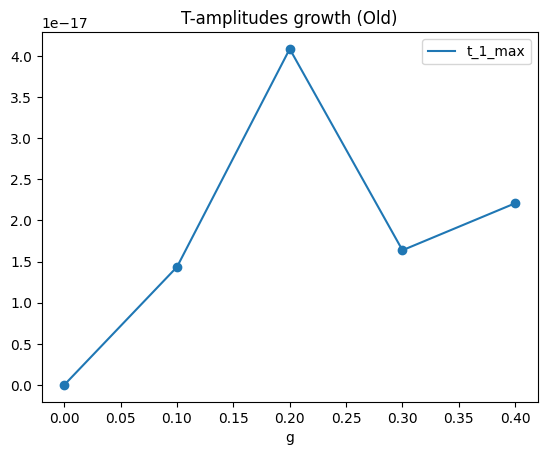

In [ ]:
plt.plot(g_arr, t_1_arr, label=f"t_1_max")
plt.scatter(g_arr, t_1_arr)
# plt.plot(g_arr, t_2_arr, label=f"t_2_max")
# plt.scatter(g_arr, t_2_arr)
plt.title("T-amplitudes growth (Old)")
plt.xlabel("g")
plt.ylabel("")
plt.legend()
plt.show()

## Check previous Integration

In [ ]:
g_arr_iter = np.arange(0, 0.8, 0.1)
t_1_arr_iter = np.full_like(g_arr_iter, 0)
t_2_arr_iter = np.full_like(g_arr_iter, 0)

state = 11
state_NO = 5

site_orig = 3
site_system = 5

periodic = True

In [ ]:
for i in range(g_arr_iter.shape[0]-3):
    g = g_arr_iter[i]

    K, V = rotor_operators(state, g)
    H = hamiltonian_dense(site_orig, K, V, V, periodic)
    eig_val, eig_vec = np.linalg.eigh(H)

    K_NO, V_NO, _, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

    V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

    _, _, _, t_1, t_2 = integration_scheme_fast(site_system, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=10)

    t_1_arr_iter[i] = np.max(t_1)
    t_2_arr_iter[i] = np.max(t_2)


0.0
1e-06
1.1e-05
0.00011099999999999999
0.001111
0.011111
0.11111099999999997
0.611111
1.111111
1.611111
2.111111
2.611111
3.111111
3.611111
4.111111
4.611111
5.111111
5.611111
6.111111
6.611111
7.111111
7.611111
8.111111000000001
8.611111000000001
9.111111000000001
9.611111000000001


/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_19183/2241498795.py:14: ComplexWarning: Casting complex values to real discards the imaginary part
  t_1_arr_iter[i] = np.max(t_1)
/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_19183/2241498795.py:15: ComplexWarning: Casting complex values to real discards the imaginary part
  t_2_arr_iter[i] = np.max(t_2)


0.0
9.999999999999999e-05
0.0011
0.0111
0.09998208681003422
0.18635919099878945
0.2830850072688851
0.3912950214677566
0.5139126413578308
0.6531507040842425
0.8098191523110367
0.983502484602467
1.174342923669431
1.383535490723697
1.6125089543469697
1.8624462894528842
2.1346707920934405
2.4313905324922516
2.756001653705691
3.1127017606040495
3.5056034921170993
3.937812469711747
4.411412960369292
4.911412960369292
5.411412960369292
5.911412960369292
6.411412960369292
6.911412960369292
7.411412960369292
7.911412960369292
8.411412960369292
8.911412960369292
9.411412960369292
9.911412960369292
0.0
9.999999999999999e-05
0.0011
0.0111
0.0845533988100203
0.15652700520209742
0.23488153049210536
0.32027244996199683
0.4143471145875004
0.5187330249901843
0.6347092273760041
0.7627740531693361
0.9026024260098349
1.0539952895088436
1.2177686172225155
1.395916792683285
1.5914682294808027
1.8082094418982055
2.0501203501742924
2.3207570715773604
2.623431826085031
2.9621028615268443
3.3411045024352584
3.7

In [ ]:
for i in range(g_arr_iter.shape[0]-3):
    g = g_arr_iter[i]

    K, V = rotor_operators(state, g)
    H = hamiltonian_dense(site_orig, K, V, V, periodic)
    eig_val, eig_vec = np.linalg.eigh(H)

    K_NO, V_NO, _, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

    V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

    _, _, _, t_1, t_2 = integration_scheme(site_system, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=10)

    t_1_arr_iter[i] = np.max(t_1)
    t_2_arr_iter[i] = np.max(t_2)


0.0
1e-06
1.1e-05
0.00011099999999999999
0.001111
0.011111
0.11111099999999997
0.611111
1.111111
1.611111
2.111111
2.611111
3.111111
3.611111
4.111111
4.611111
5.111111
5.611111
6.111111
6.611111
7.111111
7.611111
8.111111000000001
8.611111000000001
9.111111000000001
9.611111000000001
314


/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_19183/230184169.py:14: ComplexWarning: Casting complex values to real discards the imaginary part
  t_1_arr_iter[i] = np.max(t_1)
/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_19183/230184169.py:15: ComplexWarning: Casting complex values to real discards the imaginary part
  t_2_arr_iter[i] = np.max(t_2)


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.47370861621470906
0.8737697710166814
1.3737697710166814
1.8737697710166814
2.3737697710166814
2.8737697710166814
3.3737697710166814
3.8737697710166814
4.373769771016681
4.873769771016681
5.373769771016681
5.873769771016681
6.373769771016681
6.873769771016681
7.373769771016681
7.873769771016681
8.373769771016681
8.873769771016681
9.373769771016681
9.873769771016681
616
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.4115185909335022
0.7388772637380083
1.2119864689499957
1.7119864689499957
2.2119864689499957
2.7119864689499957
3.2119864689499957
3.7119864689499957
4.211986468949996
4.711986468949996
5.211986468949996
5.711986468949996
6.211986468949996
6.711986468949996
7.211986468949996
7.711986468949996
8.211986468949995
8.711986468949995
9.211986468949995
9.711986468949995
918
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.38560855486154755
0.6808574819507693
1.0938111045074794
1.5938111045074794
2.0938111045074796
2.5938111045074796

In [ ]:
K, V = rotor_operators(state, 0.8)
H = hamiltonian_dense(site_orig, K, V, V, False)
eig_val, eig_vec = np.linalg.eigh(H)

K_NO, V_NO, _, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

In [ ]:
_, _, _, t_1_fast, t_2_fast = integration_scheme_fast(site_system, state_NO, K_NO, V_NO, V_NO, periodic=False, t_final=10)

0.0
9.999999999999999e-05
0.0011
0.0111
0.07072755456649354
0.12986715224024772
0.19156048350478924
0.25578559745368823
0.3228274694654809
0.39314005570005905
0.46749182755352253
0.5467621128087939
0.6316049896944053
0.7218582826879794
0.8160088100055501
0.9156483908900089
1.0220626761505127
1.1333680342368684
1.2447163157316512
1.3522134388839235
1.45491695332809
1.5534490213487775
1.648622944559112
1.7409897097469644
1.83083925113024
1.9182920096947669
2.003372068900563
2.0860612057758945
2.1665072009698876
2.2444197529974073
2.319559082258795
2.3917193751842425
2.4606896424961264
2.526239355090718
2.5881145507200443
2.6460482147429953
2.699786985746959
2.749148931883572
2.794024986434753
2.8300814651447026
2.862483748867557
2.8914960230813147
2.9173994903321043
2.940473406903149
2.960985324664878
2.9791853567533377
2.9953050101704046
3.0095593833373777
3.0221504285958494
3.0332689707642553
3.0430943664312124
3.05179236323804
3.0595126917045192
3.0663876463298676
3.072532049503087
3.

In [ ]:
_, _, _, t_1_slow, t_2_slow = integration_scheme(site_system, state_NO, K_NO, V_NO, V_NO, periodic=False, t_final=10)

0.0
9.999999999999999e-05
0.0011
0.0111
0.07365213561780776
0.13504559167835214
0.19763087116235728
0.2618453687386257
0.328396083357682
0.3981472336662947
0.47205839159043034
0.5508053261182944
0.6343800142280701
0.7216279291808742
0.8103506099750198
0.904507393522685
1.0042290870292558
1.1093731142355006
1.2188603725168716
1.330796663138462
1.4433993319605618
1.5555569209742848
1.666763151737756
1.7768297087558347
1.8856666256993717
1.9931635086452275
2.099127474639255
2.204232766338742
2.3085541088068493
2.4120610238038194
2.5147474564509933
2.616613368997029
2.7176571055917194
2.8178747169696683
2.917262102709689
3.015818146168608
3.113548212051208
3.2104679799910683
3.3066076653113656
3.4020166620564773
3.4967683466590507
3.5909643625658036
3.684737105681446
3.7782488812458825
3.871686498603494
3.965251109537673
4.059145105120085
4.153559299540956
4.248663370547533
4.3446014062241
4.441492052064081
4.539431947588833
4.638500935779931
4.73876747161506
4.8402938147279775
4.943140585

In [ ]:
np.max(np.abs(t_1_slow))

np.float64(0.11911806659439209)

In [ ]:
np.max(np.abs(t_1_fast))

np.float64(0.6647318435642595)

In [ ]:
t_1_slow[0]

array([[ 0.000000039263+0.j],
       [-0.            +0.j],
       [-0.058370602238+0.j],
       [ 0.            +0.j]])

In [ ]:
t_1_fast[0]

array([ 0.494768043818+0.j, -0.            +0.j, -0.008071798088+0.j,  0.            +0.j])

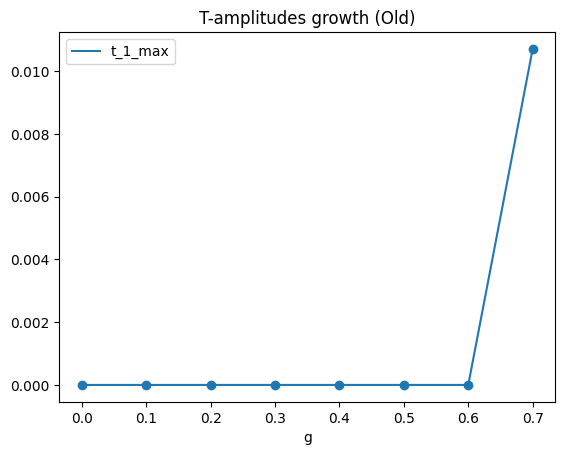

In [ ]:
plt.plot(g_arr_iter, t_1_arr_iter, label=f"t_1_max")
plt.scatter(g_arr_iter, t_1_arr_iter)
# plt.plot(g_arr_iter, t_2_arr_iter, label=f"t_2_max")
# plt.scatter(g_arr_iter, t_2_arr_iter)
plt.title("T-amplitudes growth (Old)")
plt.xlabel("g")
plt.ylabel("")
plt.legend()
plt.show()

## Check new

In [ ]:
g_arr_new = np.arange(0, 1.3, 0.1)
t_1_arr_new = np.full_like(g_arr, 0)
t_2_arr_new = np.full_like(g_arr, 0)

state = 11
state_NO = 5

site_orig = 3
site_system = 5

n_t_1_optimization = 5

In [ ]:
for i in range(g_arr_new.shape[0]):
    g = g_arr_new[i]
    print(f"g={g}")

    K, V = rotor_operators(state, g)
    H = hamiltonian_dense(site, K, V, V, False)
    eig_val, eig_vec = np.linalg.eigh(H)

    K_NO, V_NO, _, NO_basis = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

    t_1_new, t_2_new = dec_t_1(site_system, state_NO, n_t_1_optimization, K_NO, V_NO)

In [ ]:
plt.plot(g_arr_new, t_1_arr_new, label=f"t_1_max")
plt.plot(g_arr_new, t_2_arr_new, label=f"t_2_max")
plt.title(f"Combined System Comparison for g={g}")
plt.xlabel("Beta")
plt.ylabel("Energy")
plt.legend()
plt.show()

# Graphs

In [5]:
state = 11
state_NO = 5

site = 5

periodic = True

angle_arr = np.array([0, np.pi/6, np.pi/3, np.pi/2])
g_arr = np.arange(0.2, 1.7, 0.2)
g_arr_full = np.concatenate((np.array([0]), g_arr))
energy_arr = np.zeros((angle_arr.shape[0], g_arr_full.shape[0]))
t_1_max_arr = np.zeros((angle_arr.shape[0], g_arr_full.shape[0]))
t_2_max_arr = np.zeros((angle_arr.shape[0], g_arr_full.shape[0]))

In [6]:
for j, angle in enumerate(angle_arr):
    print(f"-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-. Angle = {angle} -.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.")
    for i, g in enumerate(g_arr):

        K, V = rotor_operators(state, g, psi_twist=angle)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)

        K_NO, V_NO, _, NO_basis = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        print(f"------------------------------ g = {g} ------------------------------")
        E, _, _= dec_t_1(site, state_NO, K_NO, V_NO, periodic)

        energy_arr[j, i+1] = E

-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-. Angle = 0.0 -.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
------------------------------ g = 0.2 ------------------------------
1346
Iteration: 0 t_1 - 0.002378005370698594
Iteration: 0 t_2 - 0.10284035546543732


/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_16861/1173419831.py:2: ComplexWarning: Casting complex values to real discards the imaginary part
  v = np.asarray(v, dtype=float)


2692
Iteration: 1 t_1 - 8.080652923320086e-06
Iteration: 1 t_2 - 0.08574551091294781
4038
Iteration: 2 t_1 - 2.4611649194848074e-08
Iteration: 2 t_2 - 0.08981085946654362
5384
Iteration: 3 t_1 - 9.429050730834527e-11
Iteration: 3 t_2 - 0.05248699514975722
6730
Iteration: 4 t_1 - 3.500514333374107e-13
Iteration: 4 t_2 - 0.07704880370413263
8076
Iteration: 5 t_1 - 1.353149255768222e-15
Iteration: 5 t_2 - 0.0898791053016413
------------------------------ g = 0.4 ------------------------------
9478
Iteration: 0 t_1 - 0.011437051258121306
Iteration: 0 t_2 - 0.2531329714290922
10866
Iteration: 1 t_1 - 0.0003150947567749489
Iteration: 1 t_2 - 0.1326075725610241
12254
Iteration: 2 t_1 - 1.702441439420653e-05
Iteration: 2 t_2 - 0.2094636393396296
13656
Iteration: 3 t_1 - 7.126410761517822e-07
Iteration: 3 t_2 - 0.22417607845809187
15044
Iteration: 4 t_1 - 2.5750373029404016e-08
Iteration: 4 t_2 - 0.1866329797183838
16432
Iteration: 5 t_1 - 9.126032843915272e-10
Iteration: 5 t_2 - 0.155720414151

In [7]:
energy_old_arr = np.zeros((angle_arr.shape[0], g_arr_full.shape[0]))

In [11]:
for j, angle in enumerate(angle_arr):
    print(f"-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-. Angle = {angle} -.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.")
    for i, g in enumerate(g_arr):

        K, V = rotor_operators(state, g, psi_twist=angle)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)

        K_NO, V_NO, _, NO_basis = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        print(f"------------------------------ g = {g} ------------------------------")
        energy, _, _, t_1_updated, t_2_updated = integration_scheme(site, state_NO, K_NO, V_NO.reshape(state_NO, state_NO, state_NO, state_NO), V_NO.reshape(state_NO, state_NO, state_NO, state_NO), periodic=periodic, t_final=40)

        energy_old_arr[j, i+1] = energy[-1]

-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-. Angle = 0.0 -.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
------------------------------ g = 0.2 ------------------------------
307374
------------------------------ g = 0.4 ------------------------------
308776
------------------------------ g = 0.6000000000000001 ------------------------------
311498
------------------------------ g = 0.8 ------------------------------
314208
------------------------------ g = 1.0 ------------------------------
316784
------------------------------ g = 1.2000000000000002 ------------------------------
319778
------------------------------ g = 1.4000000000000001 ------------------------------
322764
------------------------------ g = 1.6 ------------------------------
325998
-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-. Angle = 0.5235987755982988 -.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.-.
------------------------------ g = 0.2 ------------------------------
327330
------------------------------ g = 0.4 ------------------------------
328690
------

In [16]:
g = 1.6
angle = np.pi / 2

In [17]:
K, V = rotor_operators(state, g, psi_twist=angle)
H = hamiltonian_dense(3, K, V, V, periodic)
eig_val, eig_vec = np.linalg.eigh(H)

K_NO, V_NO, _, NO_basis = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

print(f"------------------------------ g = {g} ------------------------------")
E, _, _= dec_t_1(site, state_NO, K_NO, V_NO, periodic)

------------------------------ g = 1.6 ------------------------------
366364
Iteration: 0 t_1 - 2.0510588076504236e-16
Iteration: 0 t_2 - 0.2115678470819979


/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_16861/1173419831.py:2: ComplexWarning: Casting complex values to real discards the imaginary part
  v = np.asarray(v, dtype=float)


367808
Iteration: 1 t_1 - 1.708796479936589e-16
Iteration: 1 t_2 - 0.14477379172825447
369266
Iteration: 2 t_1 - 3.745911372474695e-16
Iteration: 2 t_2 - 0.15659158113117552
370710
Iteration: 3 t_1 - 4.273197151882829e-16
Iteration: 3 t_2 - 0.1748101856777321
372154
Iteration: 4 t_1 - 1.1651353985417295e-16
Iteration: 4 t_2 - 0.1939601472065286
373598
Iteration: 5 t_1 - 2.204728397453275e-16
Iteration: 5 t_2 - 0.2254795222595256


In [18]:
E

np.float64(40.0)

In [21]:
energy_arr[2,-1] = E

In [22]:
angle_plot_list = np.array([0, 30, 60, 90])

show_legend = False

line_width = 1.8
marker_size = 6.0
marker_edge_width = 1.2
markevery = 1

label_fontsize = 16
tick_fontsize = 13

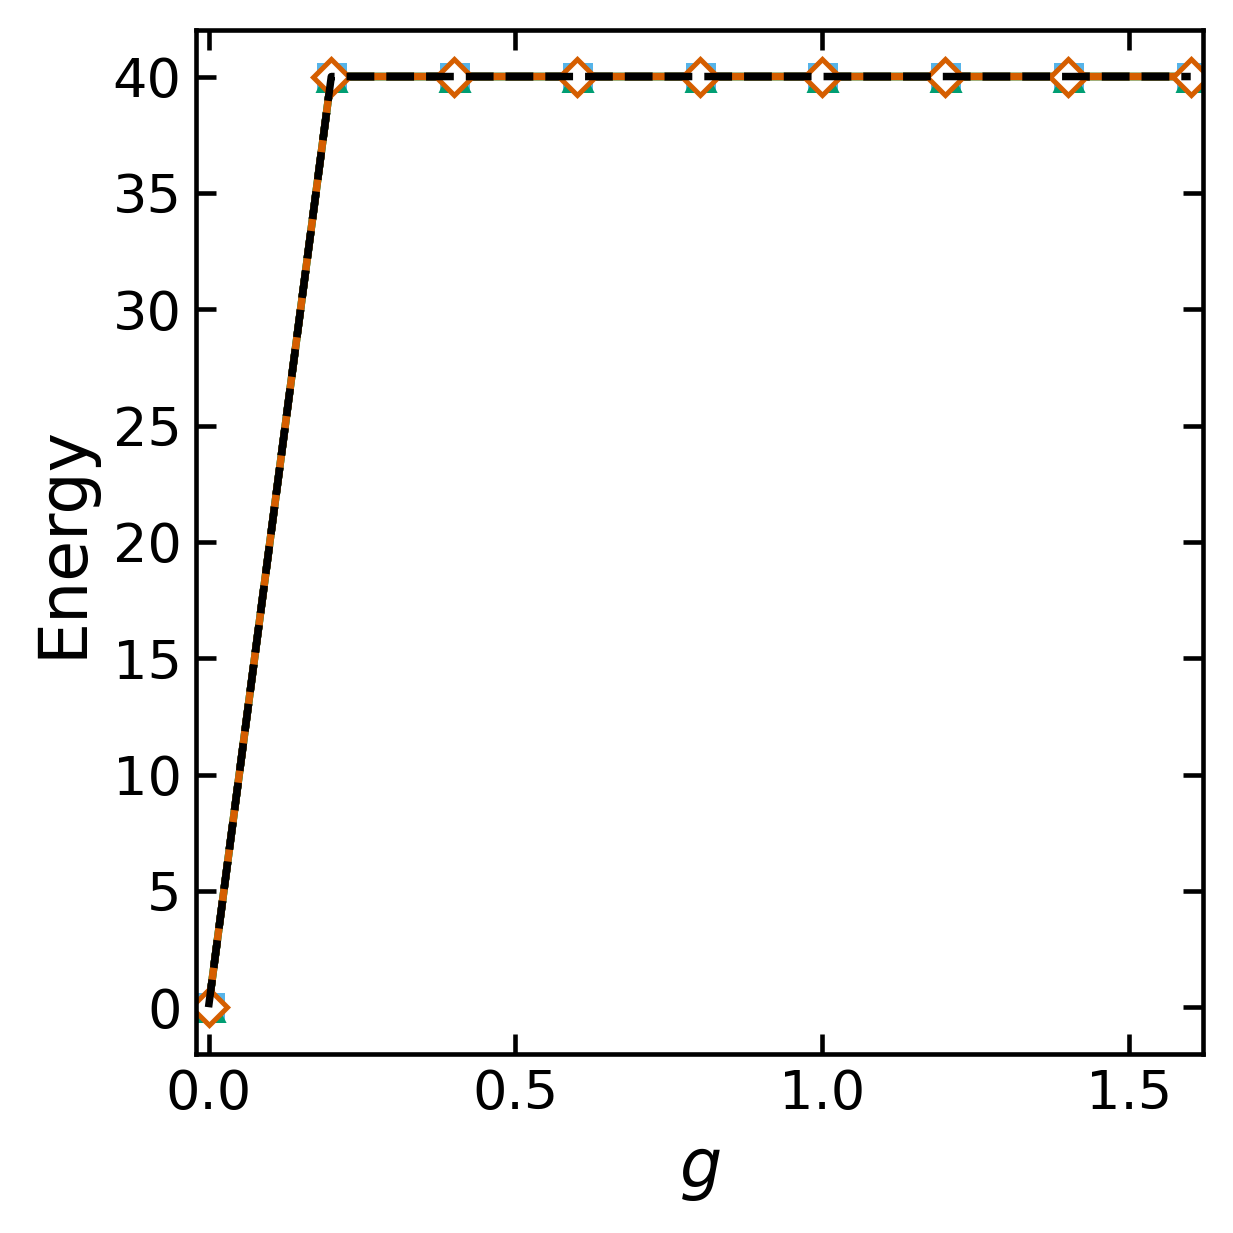

In [23]:
g_fine = g_arr_full

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": tick_fontsize,
    "axes.linewidth": 1.1,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

color_list = [
    "#DBE600",
    "#56B4E9",
    "#009E73",
    "#D55E00",
    "#0072B2",
    "#CC79A7",
    "#000000",
]

marker_list = ["o", "s", "^", "D", "v", "P", "X"]

fig1, ax1 = plt.subplots(
    figsize=(4.3, 4.3),
    dpi=300,
)

for i, angle_deg in enumerate(angle_plot_list):
    label = angle_deg

    E_new = energy_arr[i]
    E_old = energy_old_arr[i]

    ax1.plot(
        g_fine,
        E_new,
        lw=line_width,
        color=color_list[i],
    )

    ax1.plot(
        g_fine,
        E_new,
        linestyle="None",
        marker=marker_list[i],
        markersize=marker_size,
        markerfacecolor="white",
        markeredgecolor=color_list[i],
        markeredgewidth=marker_edge_width,
        markevery=markevery,
        label=rf"$\gamma = {angle_deg:.0f}^\circ$",
    )

    ax1.plot(
    g_fine,
    E_old,
    linestyle="--",
    lw=line_width,
    color="black",
    label="Extra line",
    )

ax1.set_xlim(g_fine.min() - 0.02, g_fine.max() + 0.02)

ax1.set_xlabel(r"$g$", fontsize=label_fontsize)
ax1.set_ylabel(r"Energy", fontsize=label_fontsize)

ax1.tick_params(
    axis="both",
    which="major",
    labelsize=tick_fontsize,
    length=4.8,
    width=1.1,
)

if show_legend:
    ax1.legend(frameon=False, fontsize=10)

fig1.tight_layout()

plt.show()

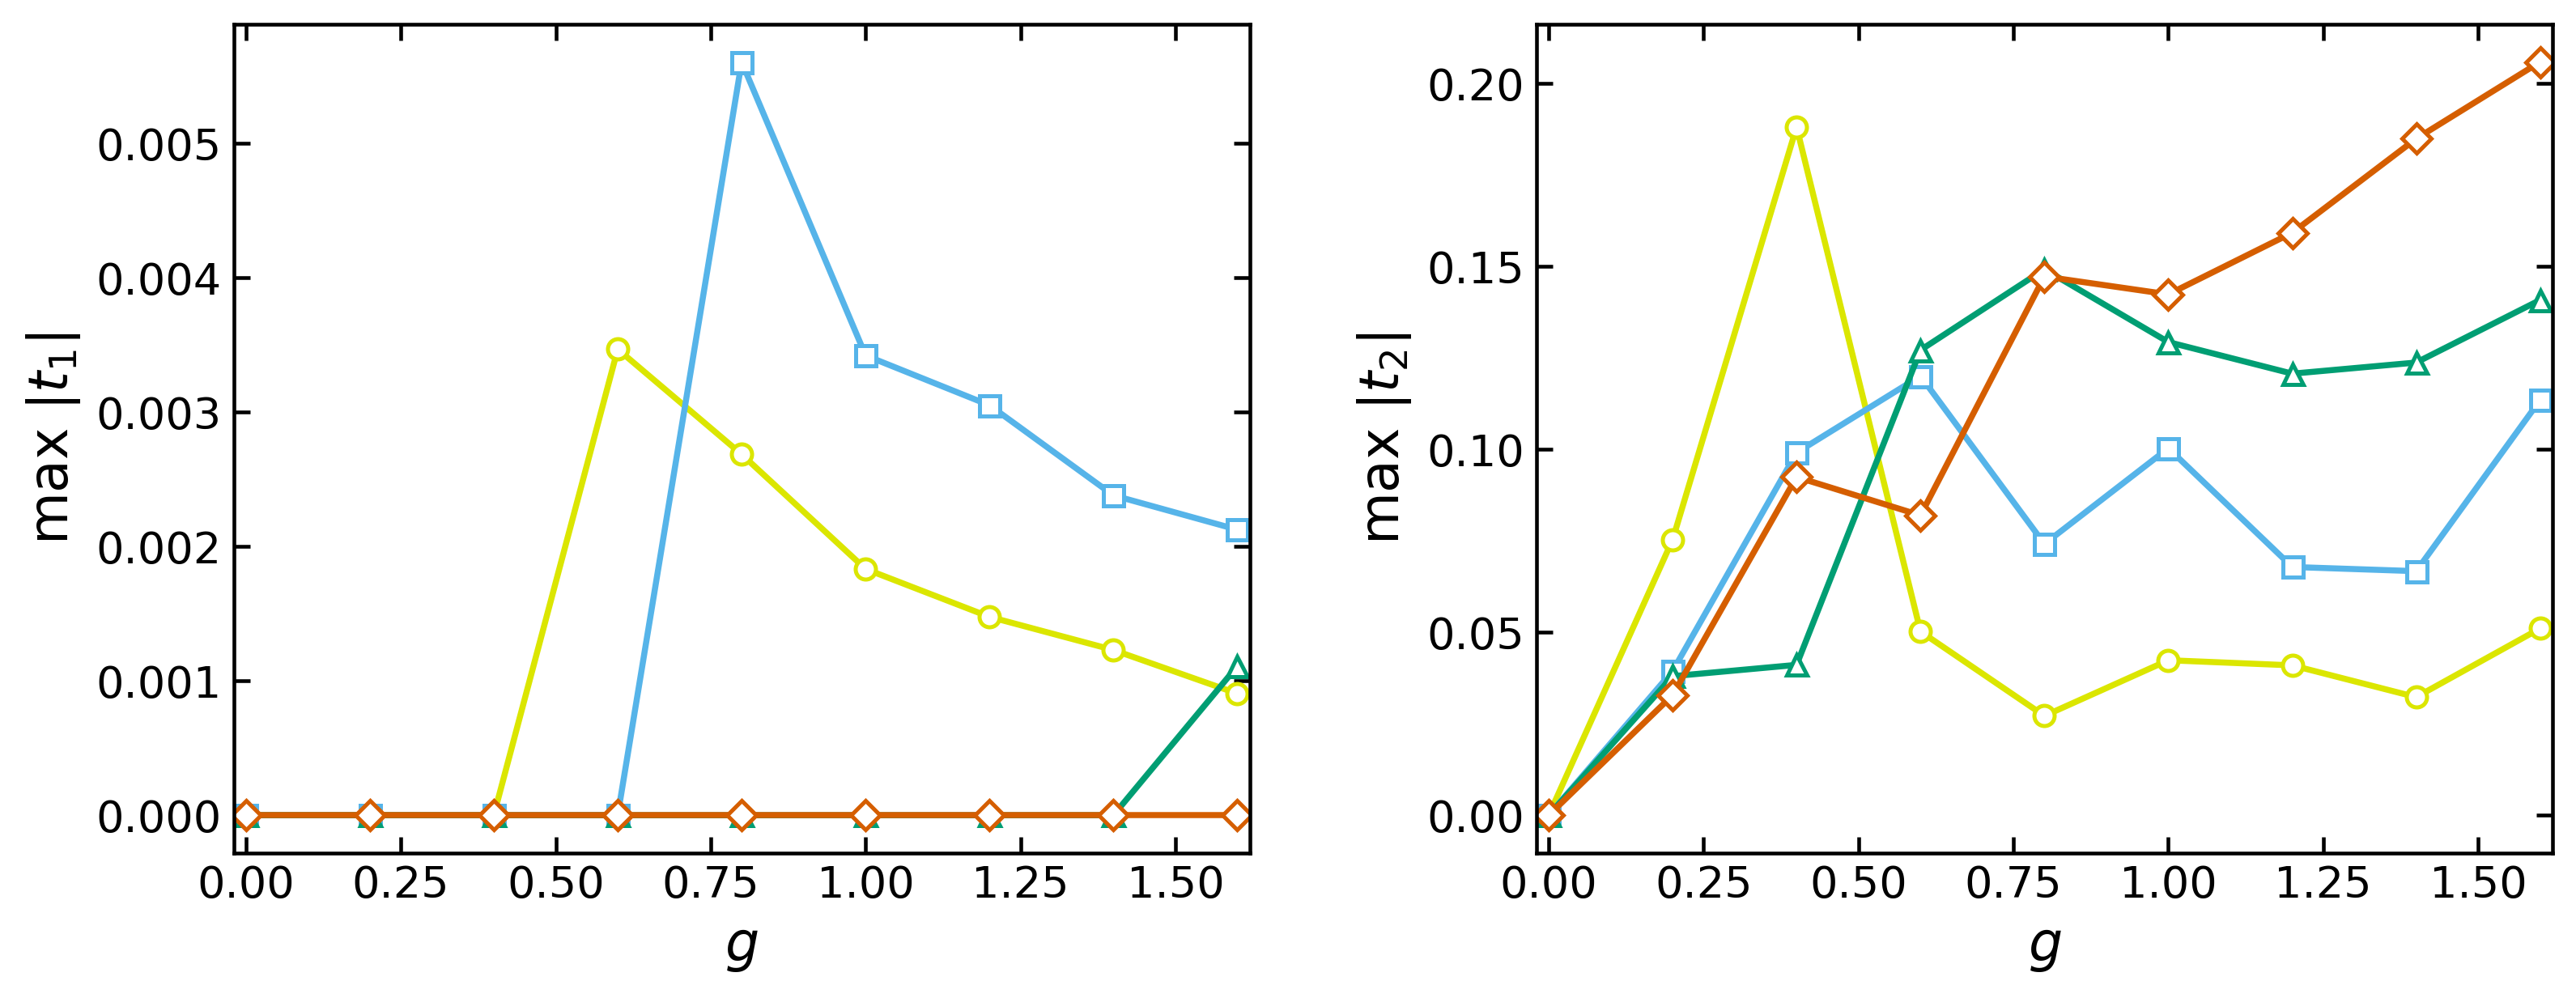

In [ ]:
g_fine = g_arr_full

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": tick_fontsize,
    "axes.linewidth": 1.1,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

color_list = [
    "#DBE600",
    "#56B4E9",
    "#009E73",
    "#D55E00",
    "#0072B2",
    "#CC79A7",
    "#000000",
]

marker_list = ["o", "s", "^", "D", "v", "P", "X"]

fig1, (ax1, ax2) = plt.subplots(
        1,
        2,
        figsize=(10.8, 4.3),
        dpi=300,
        sharex=True,
)

for i, angle_deg in enumerate(angle_plot_list):
    label = angle_deg

    max_t1 = t_1_max_arr[i]
    max_t2 = t_2_max_arr[i]

    ax1.plot(
        g_fine,
        max_t1,
        lw=line_width,
        color=color_list[i],
    )

    ax1.plot(
        g_fine,
        max_t1,
        linestyle="None",
        marker=marker_list[i],
        markersize=marker_size,
        markerfacecolor="white",
        markeredgecolor=color_list[i],
        markeredgewidth=marker_edge_width,
        markevery=markevery,
        label=rf"$\gamma = {angle_deg:.0f}^\circ$",
    )

    ax2.plot(
        g_fine,
        max_t2,
        lw=line_width,
        color=color_list[i],
    )

    # ax2.plot(
    #     g_fine,
    #     max_t2,
    #     linestyle="None",
    #     marker=marker_list[i],
    #     markersize=marker_size,
    #     markerfacecolor="white",
    #     markeredgecolor=color_list[i],
    #     markeredgewidth=marker_edge_width,
    #     markevery=markevery,
    #     label=rf"$\gamma = {angle_deg:.0f}^\circ$",
    # )

ax1.set_xlim(g_fine.min() - 0.02, g_fine.max() + 0.02)

ax1.set_xlabel(r"$g$", fontsize=label_fontsize)
# ax2.set_xlabel(r"$g$", fontsize=label_fontsize)

ax1.set_ylabel(r"max $|t_1|$", fontsize=label_fontsize)
# ax2.set_ylabel(r"max $|t_2|$", fontsize=label_fontsize)

for ax in (ax1):
    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
        length=4.8,
        width=1.1,
    )

if show_legend:
    ax2.legend(frameon=False, fontsize=10)

fig1.tight_layout(w_pad=2.4)

plt.show()

# Graph Rotors

In [5]:
state = 11
state_NO = 5

site = 6
site_comb = 2

g = 0.8
periodic = False

In [6]:
K, V = rotor_operators(state, g)
H = hamiltonian_dense(3, K, V, V, periodic)
eig_val, eig_vec = np.linalg.eigh(H)
K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

In [7]:
# K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K_NO, V_NO)

# V_comb_xy = V_comb_xy.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)
# V_comb_yx = V_comb_yx.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)

In [8]:
# beta_s, energy, _, t_1_s, t_2_s = integration_scheme(site, state_NO**site_comb, K_comb, V_comb_xy, V_comb_yx, periodic=periodic, t_final=40)

In [9]:
V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

In [10]:
beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=5)

t: 0.0
residual ratio: 0.9997716138139615
max r_2 before:     8.5739022994e-01    3.7070234955e-01
max r_2 after:     8.5719805854e-01    3.7064078357e-01    1.4699064952e-04
r_2 before:
    8.5739022994e-01    3.7070234955e-01
           (1, 0, 0)           (1, 1, 1)
r_2 after:
    8.5719805854e-01    3.7064078357e-01    3.8232587862e-05    3.1998235260e-05    1.4699064952e-04    2.7479482092e-05
           (1, 0, 0)           (1, 1, 1)           (1, 2, 2)           (1, 3, 3)           (2, 0, 0)           (2, 1, 1)
------------------------------------------------------------------------------------
t: 9.999999999999999e-05
residual ratio: 0.997719413442542
max r_2 before:     8.5719805854e-01    3.7064078357e-01    1.4699064952e-04
max r_2 after:     8.5527834554e-01    3.7002480394e-01    1.6132779389e-03
r_2 before:
    8.5719805854e-01    3.7064078357e-01    3.8232587862e-05    3.1998235260e-05    1.4699064952e-04    2.7479482092e-05
           (1, 0, 0)           (1, 1, 1)        

KeyboardInterrupt: 

In [ ]:
energy[-1]

np.complex128(-0.475578222458008+0j)

In [ ]:
g_arr = np.arange(0, 1.7, 0.2)

## Comb 1

In [6]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [7]:
state = 11
state_NO = 5

site_comb = 1

periodic = True

In [ ]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme(site, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site = 12 ------------------------------
------------------------------ g = 0.2 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.2473388857511779
0.38496835571954324
0.52790450629341
0.6776469365863834
0.83561439396989
1.0032193998487695
1.1819721583732063
1.3735650760316187
1.5799717809616936
1.8035601047742613
2.0471834559682205
2.314183456808675
2.608232493791009
2.9329884214087185
3.2916448829051124
3.6866309029437234
4.1197690998002425
4.5929152988392135
5.0929152988392135
5.5929152988392135
6.0929152988392135
6.5929152988392135
7.0929152988392135
7.5929152988392135
8.092915298839213
8.592915298839213
9.092915298839213
9.592915298839213
10.092915298839213
10.592915298839213
11.092915298839213
11.592915298839213
12.092915298839213
12.592915298839213
13.092915298839213
13.592915298839213
14.092915298839213
14.592915298839213
15.092915298839213
15.592915298839213
16.092915298839213
16.592915298839213
17.092915298839213
17.

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_46296/3936849308.py:15: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[i ,j] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.2109312806703125
0.3131226881084498
0.4183674061013959
0.528603325585964
0.6459635630954366
0.7723971407961655
0.9093908773824095
1.0582569191094437
1.2205310409732995
1.3976500815385446
1.5902995806391673
1.7986528313497419
2.0239804894046087
2.2700792371902505
2.5427283607309916
2.8478679797050432
3.1899140629659293
3.5712468641666733
3.9959738393175575
4.464635268952202
4.877184801524118
5.2322713311087155
5.538118633286805
5.802233977680215
6.030870767058117
6.22919782648312
6.4015197768206695
6.551453105533676
6.682058621563808
6.795941816450649
6.895330556219017
6.982136542797122
7.058004834607879
7.124354334277791
7.182411275080974
7.233237168515243
7.277752295608936
7.316755562473334
7.350941355221994
7.380913895622005
7.407199500379666
7.4302570728837845
7.450487098652479
7.468239371737538
7.483819641446695
7.4974953403372435
7.509500528231933
7.5200401669149795
7.529293822073637
7.537418874353681
7.544553308846636
7.55081814176

## Comb 2

In [9]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [10]:
state = 11
state_NO = 3

site_comb = 2

periodic = True

In [11]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K_NO, V_NO)

        V_comb_xy = V_comb_xy.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)
        V_comb_yx = V_comb_yx.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO**site_comb, K_comb, V_comb_xy, V_comb_yx, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site = 12 ------------------------------
------------------------------ g = 0.2 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.26817757346240123
0.4259085884395297
0.5904528824897282
0.7637400084847477
0.9476141263936625
1.1440281009322346
1.3553115952715968
1.5844487413188948
1.835372676372835
2.1131142932097045
2.4235378355466564
2.772458808506073
3.164217673902046
3.600744900287434
4.082752515762532
4.582752515762532
5.082752515762532
5.582752515762532
6.082752515762532
6.582752515762532
7.082752515762532
7.582752515762532
8.082752515762532
8.582752515762532
9.082752515762532
9.582752515762532
10.082752515762532
10.582752515762532
11.082752515762532
11.582752515762532
12.082752515762532
12.582752515762532
13.082752515762532
13.582752515762532
14.082752515762532
14.582752515762532
15.082752515762532
15.582752515762532
16.082752515762532
16.582752515762532
17.082752515762532
17.582752515762532
18.082752515762532
18.582752

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_46296/2889326565.py:18: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[i ,j] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.2314021020905478
0.3521877520073235
0.47646800531240735
0.6070401813330137
0.7466433467052425
0.8976856445627334
1.062079317607627
1.2417014109490236
1.439025790934626
1.6572991388545473
1.9002975398683608
2.1717318285690395
2.4742075625103834
2.8086026487244027
3.1755307721164665
3.5777827431619986
4.020584647118053
4.510077467391035
5.010077467391035
5.510077467391035
6.010077467391035
6.510077467391035
7.010077467391035
7.510077467391035
8.010077467391035
8.510077467391035
9.010077467391035
9.510077467391035
10.010077467391035
10.510077467391035
11.010077467391035
11.510077467391035
12.010077467391035
12.510077467391035
13.010077467391035
13.510077467391035
14.010077467391035
14.510077467391035
15.010077467391035
15.510077467391035
16.010077467391035
16.510077467391035
17.010077467391035
17.510077467391035
18.010077467391035
18.510077467391035
19.010077467391035
19.510077467391035
20.010077467391035
20.510077467391035
21.0100774673910

KeyboardInterrupt: 

## Comb 3

In [ ]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [ ]:
state = 11
state_NO = 3

site_comb = 3

periodic = True

In [ ]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K_NO, V_NO)

        V_comb_xy = V_comb_xy.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)
        V_comb_yx = V_comb_yx.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO**site_comb, K_comb, V_comb_xy, V_comb_yx, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site Combined = 3 ------------------------------
------------------------------ Site = 8 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25327191398039894
0.40182620563377835
0.5627368784930344
0.7380055558041045
0.9310014450178297
1.1461803735356066
1.388904204949892
1.6641755786502188
1.9747067387013983
2.321069254054947
2.7049423093825444
3.1305543092573043
3.60322532214482
4.103225322144819
4.603225322144819
5.103225322144819
5.603225322144819
6.103225322144819
6.603225322144819
7.103225322144819
7.603225322144819
8.10322532214482
8.60322532214482
9.10322532214482
9.60322532214482
10.10322532214482
10.60322532214482
11.10322532214482
11.60322532214482
12.10322532214482
12.60322532214482
13.10322532214482
13.60322532214482
14.10322532214482
14.60322532214482
15.10322532214482
15.60322532214482
16.10322532214482
16.60322532214482
17.10322532214482
17.60322532214482
18.10322532214482
18.60322532214482
19.10322532214482
19.

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_84144/3119394736.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[0, j, i] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25702166011016
0.4092499456607657
0.5744856724163948
0.7548706619630743
0.9540786977820441
1.1769653626331367
1.4292977470798989
1.7162212241976218
2.0402000288687163
2.401777992212891
2.803251995445828
3.249533010396606
3.7463190282705314
4.246319028270531
4.746319028270531
5.246319028270531
5.746319028270531
6.246319028270531
6.746319028270531
7.246319028270531
7.746319028270531
8.24631902827053
8.74631902827053
9.24631902827053
9.74631902827053
10.24631902827053
10.74631902827053
11.24631902827053
11.74631902827053
12.24631902827053
12.74631902827053
13.24631902827053
13.74631902827053
14.24631902827053
14.74631902827053
15.24631902827053
15.74631902827053
16.24631902827053
16.74631902827053
17.24631902827053
17.74631902827053
18.24631902827053
18.74631902827053
19.24631902827053
19.74631902827053
20.24631902827053
20.74631902827053
21.24631902827053
21.74631902827053
22.24631902827053
22.74631902827053
23.24631902827053
23.7463190282

KeyboardInterrupt: 

## Comb 4

In [ ]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [ ]:
state = 11
state_NO = 3

site_comb = 4

periodic = True

In [ ]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K_NO, V_NO)

        V_comb_xy = V_comb_xy.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)
        V_comb_yx = V_comb_yx.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO**site_comb, K_comb, V_comb_xy, V_comb_yx, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site Combined = 3 ------------------------------
------------------------------ Site = 8 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25327191398039894
0.40182620563377835
0.5627368784930344
0.7380055558041045
0.9310014450178297
1.1461803735356066
1.388904204949892
1.6641755786502188
1.9747067387013983
2.321069254054947
2.7049423093825444
3.1305543092573043
3.60322532214482
4.103225322144819
4.603225322144819
5.103225322144819
5.603225322144819
6.103225322144819
6.603225322144819
7.103225322144819
7.603225322144819
8.10322532214482
8.60322532214482
9.10322532214482
9.60322532214482
10.10322532214482
10.60322532214482
11.10322532214482
11.60322532214482
12.10322532214482
12.60322532214482
13.10322532214482
13.60322532214482
14.10322532214482
14.60322532214482
15.10322532214482
15.60322532214482
16.10322532214482
16.60322532214482
17.10322532214482
17.60322532214482
18.10322532214482
18.60322532214482
19.10322532214482
19.

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_84144/3119394736.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[0, j, i] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25702166011016
0.4092499456607657
0.5744856724163948
0.7548706619630743
0.9540786977820441
1.1769653626331367
1.4292977470798989
1.7162212241976218
2.0402000288687163
2.401777992212891
2.803251995445828
3.249533010396606
3.7463190282705314
4.246319028270531
4.746319028270531
5.246319028270531
5.746319028270531
6.246319028270531
6.746319028270531
7.246319028270531
7.746319028270531
8.24631902827053
8.74631902827053
9.24631902827053
9.74631902827053
10.24631902827053
10.74631902827053
11.24631902827053
11.74631902827053
12.24631902827053
12.74631902827053
13.24631902827053
13.74631902827053
14.24631902827053
14.74631902827053
15.24631902827053
15.74631902827053
16.24631902827053
16.74631902827053
17.24631902827053
17.74631902827053
18.24631902827053
18.74631902827053
19.24631902827053
19.74631902827053
20.24631902827053
20.74631902827053
21.24631902827053
21.74631902827053
22.24631902827053
22.74631902827053
23.24631902827053
23.7463190282

KeyboardInterrupt: 

##

In [ ]:
# Load
loaded_arr = np.load('my_array.npy')
print(loaded_arr)

In [ ]:
site_comb_plot_list = np.array([3, 4, 6])

show_legend = False

line_width = 1.8
marker_size = 6.0
marker_edge_width = 1.2
markevery = 1

label_fontsize = 16
tick_fontsize = 13

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(10.8, 8.0),
    dpi=300,
    sharex=True,
)

# Flatten the 2x2 array of axes
axes = axes.ravel()

# Data and labels for each subplot
datasets = [
    (t_1_max_arr, r"max $|t_1|$"),
    (t_2_max_arr, r"max $|t_2|$"),
    (t_3_max_arr, r"max $|t_3|$"),
    (t_4_max_arr, r"max $|t_4|$"),
]

for ax, (data_arr, ylabel) in zip(axes, datasets):

    for i, angle_deg in enumerate(site_comb_plot_list):

        ax.plot(
            g_fine,
            data_arr[i],
            lw=line_width,
            color=color_list[i],
        )

        ax.plot(
            g_fine,
            data_arr[i],
            linestyle="None",
            marker=marker_list[i],
            markersize=marker_size,
            markerfacecolor="white",
            markeredgecolor=color_list[i],
            markeredgewidth=marker_edge_width,
            markevery=markevery,
            label=rf"$\gamma = {angle_deg:.0f}^\circ$",
        )

    ax.set_xlim(g_fine.min() - 0.02, g_fine.max() + 0.02)
    ax.set_xlabel(r"$g$", fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
        length=4.8,
        width=1.1,
    )

if show_legend:
    axes[1].legend(frameon=False, fontsize=10)

fig.tight_layout(w_pad=2.4, h_pad=2.0)
plt.show()

# Graph Magnetic

In [5]:
site = 12
site_comb = 2


state = 2
state_comb = state**site_comb
state_NO = state_comb


g = 0.6
periodic = False

In [6]:
K, V = heisenberg_operators(g_val=g)
# H = hamiltonian_dense(3, K, V, V, periodic)

In [7]:
K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K, V)
# H_comb = hamiltonian_dense(3, K_comb, V_comb_xy, V_comb_yx, periodic)
# eig_val_comb, eig_vec_comb = np.linalg.eigh(H_comb)

In [8]:
# K_comb_NO, V_comb_NO_xy, V_comb_NO_yx, _ = NO_transform(state_NO, H_comb, K_comb, V_comb_xy, V_comb_yx, eig_vec_comb[:, 0])

In [9]:
eig_val_comb, eig_vec_comb = np.linalg.eigh(K_comb)

In [10]:
K_e_comb, V_e_comb_xy, V_e_comb_yx = energy_transform(K_comb, V_comb_xy, V_comb_yx)

V_e_comb_xy = V_e_comb_xy.reshape(state_comb, state_comb, state_comb, state_comb)
V_e_comb_yx = V_e_comb_yx.reshape(state_comb, state_comb, state_comb, state_comb)

1


In [11]:
# arr = np.array([[

#     [0.0, 1.23456789, 0.0],

#     [5.67890123, 0.0, -2.3456789],

#     [5.67890123, 0.0, -2.3456789],

# ],
# [

#     [0.0, 1.23456789, 0.0],

#     [5.67890123, 0.0, -2.3456789],

#     [5.67890123, 0.0, -2.3456789],

# ]])

# # Full indices of all nonzero elements

# indices = np.argwhere(arr != 0)

# # Values at those indices

# values = arr[tuple(indices.T)]

# width = 22

# # # Values

# print("".join(f"{value:>{width}.10e}" for value in values))

# # Full indices

# print("".join(

#     f"{str(tuple(map(int, idx))):>{width}}"

#     for idx in indices

# ))

In [12]:
beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_comb, K_e_comb, V_e_comb_xy, V_e_comb_yx, periodic=periodic, t_final=40)

residual ratio: 0.9997600287966755
max r_2 before: [0.6 0.6]
max r_2 after: [0.59985601296  0.59985601296  0.000071982722]
r_2 before:
   -6.0000000000e-01   -6.0000000000e-01
           (1, 0, 2)           (1, 2, 0)
r_2 after:
   -6.0000000000e-01   -6.0000000000e-01
           (1, 0, 2)           (1, 2, 0)
------------------------------------------------------------------------------------
residual ratio: 0.9976028763464809
max r_2 before: [0.59985601296  0.59985601296  0.000071982722]
max r_2 after: [0.5984175677   0.5984175677   0.000789911763]
r_2 before:
   -5.9985601296e-01    7.1974084147e-05   -5.9985601296e-01   -7.1982721987e-05   -7.1982721987e-05   -6.4782722397e-09   -6.4782722397e-09   -5.1824450504e-13   -5.1824450504e-13   -3.8866938704e-17   -3.8866938704e-17   -2.7983151183e-21   -2.7983151183e-21   -1.9587459652e-25   -1.9587459652e-25   -1.3430882863e-29   -1.3430882863e-29   -9.0654938264e-34   -9.0654938264e-34   -6.0431619639e-38   -6.0431619639e-38   -3.9873422

KeyboardInterrupt: 

In [ ]:
V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

In [ ]:
beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=40)

0.0
9.999999999999999e-05
0.0011
0.0111
0.06288161394445098
0.11595854765027971
0.17387766184218229
0.23733850403558665
0.3074939935477018
0.38314238332088757
0.4595438368491269
0.5366829162953067
0.6173519947055297
0.7031755394169092
0.791141363580221
0.8637465359154708
0.9274581056263245
0.9832099697800643
1.0319529486194563
1.0745491231558182
1.1117604275183157
1.144256177122603
1.172625169463813
1.1973885627094294
1.219017245022142
1.2378467629000196
1.2541565564380415
1.2683267101748075
1.280644620879169
1.2913518875956531
1.3006569738865192
1.3087412132357106
1.3157627420004123
1.3218595523760777
1.327152045167965
1.3317452306152358
1.3357306489891763
1.3391880544419241
1.3421868935781338
1.3447876042463462
1.3470427562033929
1.3489980524934686
1.3506932079981329
1.3521627195849786
1.3534365405846775
1.3545406708244605
1.3554976722107122
1.3563271187432675
1.3570459888852497
1.3576690073325224
1.3582089424627266
1.3586768650157521
1.359082372919705
1.3594337865909114
1.3597383185

KeyboardInterrupt: 

In [ ]:
energy[-1]

np.complex128(-0.475578222458008+0j)

In [ ]:
g_arr = np.arange(0, 1.7, 0.2)

## Comb 1

In [ ]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [ ]:
state = 11
state_NO = 5

site_comb = 1

periodic = True

In [ ]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        V_NO = V_NO.reshape(state_NO, state_NO, state_NO, state_NO)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme(site, state_NO, K_NO, V_NO, V_NO, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site = 12 ------------------------------
------------------------------ g = 0.2 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.2473388857511779
0.38496835571954324
0.52790450629341
0.6776469365863834
0.83561439396989
1.0032193998487695
1.1819721583732063
1.3735650760316187
1.5799717809616936
1.8035601047742613
2.0471834559682205
2.314183456808675
2.608232493791009
2.9329884214087185
3.2916448829051124
3.6866309029437234
4.1197690998002425
4.5929152988392135
5.0929152988392135
5.5929152988392135
6.0929152988392135
6.5929152988392135
7.0929152988392135
7.5929152988392135
8.092915298839213
8.592915298839213
9.092915298839213
9.592915298839213
10.092915298839213
10.592915298839213
11.092915298839213
11.592915298839213
12.092915298839213
12.592915298839213
13.092915298839213
13.592915298839213
14.092915298839213
14.592915298839213
15.092915298839213
15.592915298839213
16.092915298839213
16.592915298839213
17.092915298839213
17.

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_46296/3936849308.py:15: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[i ,j] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.2109312806703125
0.3131226881084498
0.4183674061013959
0.528603325585964
0.6459635630954366
0.7723971407961655
0.9093908773824095
1.0582569191094437
1.2205310409732995
1.3976500815385446
1.5902995806391673
1.7986528313497419
2.0239804894046087
2.2700792371902505
2.5427283607309916
2.8478679797050432
3.1899140629659293
3.5712468641666733
3.9959738393175575
4.464635268952202
4.877184801524118
5.2322713311087155
5.538118633286805
5.802233977680215
6.030870767058117
6.22919782648312
6.4015197768206695
6.551453105533676
6.682058621563808
6.795941816450649
6.895330556219017
6.982136542797122
7.058004834607879
7.124354334277791
7.182411275080974
7.233237168515243
7.277752295608936
7.316755562473334
7.350941355221994
7.380913895622005
7.407199500379666
7.4302570728837845
7.450487098652479
7.468239371737538
7.483819641446695
7.4974953403372435
7.509500528231933
7.5200401669149795
7.529293822073637
7.537418874353681
7.544553308846636
7.55081814176

## Comb 2

In [ ]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [ ]:
state = 11
state_NO = 3

site_comb = 2

periodic = True

In [ ]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K_NO, V_NO)

        V_comb_xy = V_comb_xy.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)
        V_comb_yx = V_comb_yx.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO**site_comb, K_comb, V_comb_xy, V_comb_yx, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site = 12 ------------------------------
------------------------------ g = 0.2 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.26817757346240123
0.4259085884395297
0.5904528824897282
0.7637400084847477
0.9476141263936625
1.1440281009322346
1.3553115952715968
1.5844487413188948
1.835372676372835
2.1131142932097045
2.4235378355466564
2.772458808506073
3.164217673902046
3.600744900287434
4.082752515762532
4.582752515762532
5.082752515762532
5.582752515762532
6.082752515762532
6.582752515762532
7.082752515762532
7.582752515762532
8.082752515762532
8.582752515762532
9.082752515762532
9.582752515762532
10.082752515762532
10.582752515762532
11.082752515762532
11.582752515762532
12.082752515762532
12.582752515762532
13.082752515762532
13.582752515762532
14.082752515762532
14.582752515762532
15.082752515762532
15.582752515762532
16.082752515762532
16.582752515762532
17.082752515762532
17.582752515762532
18.082752515762532
18.582752

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_46296/2889326565.py:18: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[i ,j] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.2314021020905478
0.3521877520073235
0.47646800531240735
0.6070401813330137
0.7466433467052425
0.8976856445627334
1.062079317607627
1.2417014109490236
1.439025790934626
1.6572991388545473
1.9002975398683608
2.1717318285690395
2.4742075625103834
2.8086026487244027
3.1755307721164665
3.5777827431619986
4.020584647118053
4.510077467391035
5.010077467391035
5.510077467391035
6.010077467391035
6.510077467391035
7.010077467391035
7.510077467391035
8.010077467391035
8.510077467391035
9.010077467391035
9.510077467391035
10.010077467391035
10.510077467391035
11.010077467391035
11.510077467391035
12.010077467391035
12.510077467391035
13.010077467391035
13.510077467391035
14.010077467391035
14.510077467391035
15.010077467391035
15.510077467391035
16.010077467391035
16.510077467391035
17.010077467391035
17.510077467391035
18.010077467391035
18.510077467391035
19.010077467391035
19.510077467391035
20.010077467391035
20.510077467391035
21.0100774673910

KeyboardInterrupt: 

## Comb 3

In [ ]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [ ]:
state = 11
state_NO = 3

site_comb = 3

periodic = True

In [ ]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K_NO, V_NO)

        V_comb_xy = V_comb_xy.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)
        V_comb_yx = V_comb_yx.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO**site_comb, K_comb, V_comb_xy, V_comb_yx, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site Combined = 3 ------------------------------
------------------------------ Site = 8 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25327191398039894
0.40182620563377835
0.5627368784930344
0.7380055558041045
0.9310014450178297
1.1461803735356066
1.388904204949892
1.6641755786502188
1.9747067387013983
2.321069254054947
2.7049423093825444
3.1305543092573043
3.60322532214482
4.103225322144819
4.603225322144819
5.103225322144819
5.603225322144819
6.103225322144819
6.603225322144819
7.103225322144819
7.603225322144819
8.10322532214482
8.60322532214482
9.10322532214482
9.60322532214482
10.10322532214482
10.60322532214482
11.10322532214482
11.60322532214482
12.10322532214482
12.60322532214482
13.10322532214482
13.60322532214482
14.10322532214482
14.60322532214482
15.10322532214482
15.60322532214482
16.10322532214482
16.60322532214482
17.10322532214482
17.60322532214482
18.10322532214482
18.60322532214482
19.10322532214482
19.

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_84144/3119394736.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[0, j, i] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25702166011016
0.4092499456607657
0.5744856724163948
0.7548706619630743
0.9540786977820441
1.1769653626331367
1.4292977470798989
1.7162212241976218
2.0402000288687163
2.401777992212891
2.803251995445828
3.249533010396606
3.7463190282705314
4.246319028270531
4.746319028270531
5.246319028270531
5.746319028270531
6.246319028270531
6.746319028270531
7.246319028270531
7.746319028270531
8.24631902827053
8.74631902827053
9.24631902827053
9.74631902827053
10.24631902827053
10.74631902827053
11.24631902827053
11.74631902827053
12.24631902827053
12.74631902827053
13.24631902827053
13.74631902827053
14.24631902827053
14.74631902827053
15.24631902827053
15.74631902827053
16.24631902827053
16.74631902827053
17.24631902827053
17.74631902827053
18.24631902827053
18.74631902827053
19.24631902827053
19.74631902827053
20.24631902827053
20.74631902827053
21.24631902827053
21.74631902827053
22.24631902827053
22.74631902827053
23.24631902827053
23.7463190282

KeyboardInterrupt: 

## Comb 4

In [ ]:
energy_arr = np.zeros((4, g_arr.shape[0]))
t_1_maximum_arr = np.zeros((4, g_arr.shape[0]))
t_2_maximum_arr = np.zeros((4, g_arr.shape[0]))

In [ ]:
state = 11
state_NO = 3

site_comb = 4

periodic = True

In [ ]:
for i in range(1, 5):
    site = 12*i
    print(f"------------------------------ Site = {site} ------------------------------")
    for j, g in enumerate(g_arr[1:]):
        print(f"------------------------------ g = {g} ------------------------------")
        K, V = rotor_operators(state, g)
        H = hamiltonian_dense(3, K, V, V, periodic)
        eig_val, eig_vec = np.linalg.eigh(H)
        K_NO, V_NO, V_NO, _ = NO_transform(state_NO, H, K, V, V, eig_vec[:, 0])

        K_comb, V_comb_xy, V_comb_yx = combine_transform(site_comb, K_NO, V_NO)

        V_comb_xy = V_comb_xy.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)
        V_comb_yx = V_comb_yx.reshape(state_NO**site_comb, state_NO**site_comb, state_NO**site_comb, state_NO**site_comb)

        beta_s, energy, _, t_1_s, t_2_s = integration_scheme_fast(site, state_NO**site_comb, K_comb, V_comb_xy, V_comb_yx, periodic=periodic, t_final=40)

        energy_arr[i ,j] = energy[-1] / site
        t_1_maximum_arr[i ,j] = np.max(np.abs(t_1_s))
        t_2_maximum_arr[i ,j] = np.max(np.abs(t_2_s))
        np.save(f'energy_comb_{site_comb}.npy', energy_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_1_maximum_arr)
        np.save(f't_1_comb_{site_comb}.npy', t_2_maximum_arr)

------------------------------ Site Combined = 3 ------------------------------
------------------------------ Site = 8 ------------------------------
0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25327191398039894
0.40182620563377835
0.5627368784930344
0.7380055558041045
0.9310014450178297
1.1461803735356066
1.388904204949892
1.6641755786502188
1.9747067387013983
2.321069254054947
2.7049423093825444
3.1305543092573043
3.60322532214482
4.103225322144819
4.603225322144819
5.103225322144819
5.603225322144819
6.103225322144819
6.603225322144819
7.103225322144819
7.603225322144819
8.10322532214482
8.60322532214482
9.10322532214482
9.60322532214482
10.10322532214482
10.60322532214482
11.10322532214482
11.60322532214482
12.10322532214482
12.60322532214482
13.10322532214482
13.60322532214482
14.10322532214482
14.60322532214482
15.10322532214482
15.60322532214482
16.10322532214482
16.60322532214482
17.10322532214482
17.60322532214482
18.10322532214482
18.60322532214482
19.10322532214482
19.

/var/folders/vt/f4sbj2d11gbbb9q5816khz2m0000gn/T/ipykernel_84144/3119394736.py:17: ComplexWarning: Casting complex values to real discards the imaginary part
  energy_arr[0, j, i] = energy[-1] / site


0.0
9.999999999999999e-05
0.0011
0.0111
0.1111
0.25702166011016
0.4092499456607657
0.5744856724163948
0.7548706619630743
0.9540786977820441
1.1769653626331367
1.4292977470798989
1.7162212241976218
2.0402000288687163
2.401777992212891
2.803251995445828
3.249533010396606
3.7463190282705314
4.246319028270531
4.746319028270531
5.246319028270531
5.746319028270531
6.246319028270531
6.746319028270531
7.246319028270531
7.746319028270531
8.24631902827053
8.74631902827053
9.24631902827053
9.74631902827053
10.24631902827053
10.74631902827053
11.24631902827053
11.74631902827053
12.24631902827053
12.74631902827053
13.24631902827053
13.74631902827053
14.24631902827053
14.74631902827053
15.24631902827053
15.74631902827053
16.24631902827053
16.74631902827053
17.24631902827053
17.74631902827053
18.24631902827053
18.74631902827053
19.24631902827053
19.74631902827053
20.24631902827053
20.74631902827053
21.24631902827053
21.74631902827053
22.24631902827053
22.74631902827053
23.24631902827053
23.7463190282

KeyboardInterrupt: 

##

In [ ]:
# Load
loaded_arr = np.load('my_array.npy')
print(loaded_arr)

In [ ]:
site_comb_plot_list = np.array([3, 4, 6])

show_legend = False

line_width = 1.8
marker_size = 6.0
marker_edge_width = 1.2
markevery = 1

label_fontsize = 16
tick_fontsize = 13

In [ ]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(10.8, 8.0),
    dpi=300,
    sharex=True,
)

# Flatten the 2x2 array of axes
axes = axes.ravel()

# Data and labels for each subplot
datasets = [
    (t_1_max_arr, r"max $|t_1|$"),
    (t_2_max_arr, r"max $|t_2|$"),
    (t_3_max_arr, r"max $|t_3|$"),
    (t_4_max_arr, r"max $|t_4|$"),
]

for ax, (data_arr, ylabel) in zip(axes, datasets):

    for i, angle_deg in enumerate(site_comb_plot_list):

        ax.plot(
            g_fine,
            data_arr[i],
            lw=line_width,
            color=color_list[i],
        )

        ax.plot(
            g_fine,
            data_arr[i],
            linestyle="None",
            marker=marker_list[i],
            markersize=marker_size,
            markerfacecolor="white",
            markeredgecolor=color_list[i],
            markeredgewidth=marker_edge_width,
            markevery=markevery,
            label=rf"$\gamma = {angle_deg:.0f}^\circ$",
        )

    ax.set_xlim(g_fine.min() - 0.02, g_fine.max() + 0.02)
    ax.set_xlabel(r"$g$", fontsize=label_fontsize)
    ax.set_ylabel(ylabel, fontsize=label_fontsize)

    ax.tick_params(
        axis="both",
        which="major",
        labelsize=tick_fontsize,
        length=4.8,
        width=1.1,
    )

if show_legend:
    axes[1].legend(frameon=False, fontsize=10)

fig.tight_layout(w_pad=2.4, h_pad=2.0)
plt.show()